This is Rachel's version of the notebook. Me and Jah will merge later.

Clean the data by eliminating rides lasting more than three hours and rides with negative duration, if
any. Long rides may correspond to bikes left undocked, and negative durations may reflect recording
errors. Report the number of rows and columns before cleaning, the number of rides removed by
each rule, and the number retained. Document any additional cleaning decisions.
1. Using the start and end times, compute each ride’s duration in minutes and plot a histogram
of ride durations.
2. What is the expected ride duration (the average ride duration)? What is the empirical variance
of ride duration? What is the probability that a ride lasts more than 20 minutes?
3. What is the probability that a ride lasts more than 20 minutes conditional on the user being
a Citi Bike member?
4. Suppose that a ride lasts more than 25 minutes. What is the probability that this ride belongs
to a Citi Bike member?
5. What is the expected ride duration of an electric bike? What is the expected ride duration of
a classic bike?
6. Suppose that a ride lasts less than 10 minutes. What is the probability that it uses an electric
bike? What is the probability that it uses a classic bike? Comment on the results.

In [ ]:
from pathlib import Path
import pandas as pd

input_dir = Path("202608-citibike-tripdata")
output_dir = Path("clean-202608-citibike-tripdata")
source_files = sorted(input_dir.glob("*.csv"))

# if not source_files:
#     raise FileNotFoundError(f"No CSV files found in {input_dir}")

# output_dir.mkdir(parents=True, exist_ok=True)
# chunk_size = 250_000
# totals = {"rows_before": 0, "over_3_hours": 0, "negative_duration": 0, "rows_retained": 0}

# for source_file in source_files:
#     output_file = output_dir / f"{source_file.stem}_cleaned.csv"
#     file_totals = {"rows_before": 0, "over_3_hours": 0, "negative_duration": 0, "rows_retained": 0}

#     # Process in chunks so the full set of large CSV files does not need to fit in memory.
#     for chunk_number, chunk in enumerate(
#         pd.read_csv(source_file, chunksize=chunk_size, low_memory=False)
#     ):
#         # Calculate ride duration from the recorded start and end timestamps.
#         duration = pd.to_datetime(chunk["ended_at"]) - pd.to_datetime(chunk["started_at"])
#         over_3_hours = duration > pd.Timedelta(hours=3)
#         negative_duration = duration < pd.Timedelta(0)

#         # Keep rides from zero through three hours; remove long and negative-duration rides.
#         cleaned_chunk = chunk.loc[~(over_3_hours | negative_duration)]

#         file_totals["rows_before"] += len(chunk)
#         file_totals["over_3_hours"] += int(over_3_hours.sum())
#         file_totals["negative_duration"] += int(negative_duration.sum())
#         file_totals["rows_retained"] += len(cleaned_chunk)
#         cleaned_chunk.to_csv(
#             output_file,
#             mode="w" if chunk_number == 0 else "a",
#             header=chunk_number == 0,
#             index=False,
#         )

#     for key in totals:
#         totals[key] += file_totals[key]

#     print(
#         f"{source_file.name}: {file_totals['rows_before']:,} rows before; "
#         f"{file_totals['over_3_hours']:,} over 3 hours removed; "
#         f"{file_totals['negative_duration']:,} negative-duration rides removed; "
#         f"{file_totals['rows_retained']:,} retained -> {output_file}"
#     )

# print("\nOverall cleaning summary")
# print(f"Rows before cleaning: {totals['rows_before']:,}")
# print(f"Columns per input file: {len(pd.read_csv(source_files[0], nrows=0).columns)}")
# print(f"Were any original rides over 3 hours? {'Yes' if totals['over_3_hours'] else 'No'}")
# print(f"Rides over 3 hours removed: {totals['over_3_hours']:,}")
# print(f"Were any original rides negative-duration? {'Yes' if totals['negative_duration'] else 'No'}")
# print(f"Rides with negative duration removed: {totals['negative_duration']:,}")
# print(f"Rows retained: {totals['rows_retained']:,}")
# print(f"Cleaned CSV files saved in: {output_dir}")

202608-citibike-tripdata_1.csv: 1,000,000 rows before; 791 over 3 hours removed; 0 negative-duration rides removed; 999,209 retained -> clean-202608-citibike-tripdata/202608-citibike-tripdata_1_cleaned.csv
202608-citibike-tripdata_2.csv: 1,000,000 rows before; 727 over 3 hours removed; 0 negative-duration rides removed; 999,273 retained -> clean-202608-citibike-tripdata/202608-citibike-tripdata_2_cleaned.csv
202608-citibike-tripdata_3.csv: 1,000,000 rows before; 1,904 over 3 hours removed; 0 negative-duration rides removed; 998,096 retained -> clean-202608-citibike-tripdata/202608-citibike-tripdata_3_cleaned.csv
202608-citibike-tripdata_4.csv: 1,000,000 rows before; 1,462 over 3 hours removed; 0 negative-duration rides removed; 998,538 retained -> clean-202608-citibike-tripdata/202608-citibike-tripdata_4_cleaned.csv
202608-citibike-tripdata_5.csv: 1,000,000 rows before; 961 over 3 hours removed; 0 negative-duration rides removed; 999,039 retained -> clean-202608-citibike-tripdata/20260

1. Using the start and end times, compute each ride’s duration in minutes and plot a histogram
of ride durations.


In [2]:
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt

csv_files = glob.glob(os.path.join('clean-202608-citibike-tripdata', "*.csv"))

df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)

print(df.shape)
df.head()

/var/folders/6k/nlcls0s570j_56t476_5msgm0000gn/T/ipykernel_21622/3509233622.py:9: DtypeWarning: Columns (7: end_station_id) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)


(5240216, 13)


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,E4A8132DACF670C3,electric_bike,2026-08-10 14:31:22.100,2026-08-10 14:37:37.034,E 33 St & 5 Ave,6322.01,W 24 St & 7 Ave,6257.03,40.747659,-73.984907,40.744876,-73.995299,member
1,8382768C05C30BB4,electric_bike,2026-08-10 08:04:28.348,2026-08-10 08:33:27.680,Emerson Pl & Myrtle Ave,4683.02,W 24 St & 7 Ave,6257.03,40.693631,-73.962236,40.744876,-73.995299,member
2,3A1C43832BBE4FCD,classic_bike,2026-08-08 19:36:32.350,2026-08-08 19:43:47.890,Broadway & E 19 St,5980.11,W 24 St & 7 Ave,6257.03,40.738290,-73.990060,40.744876,-73.995299,member
3,5C9BC6DFC4DEA183,electric_bike,2026-08-05 14:34:27.749,2026-08-05 14:46:23.526,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member
4,355579CC64D1BE20,electric_bike,2026-08-01 14:16:44.531,2026-08-01 14:29:39.539,Sterling Pl & Bedford Ave,3993.03,Cumberland St & Lafayette Ave,4428.02,40.672695,-73.954131,40.687534,-73.972652,member


Text(0, 0.5, 'Frequency')

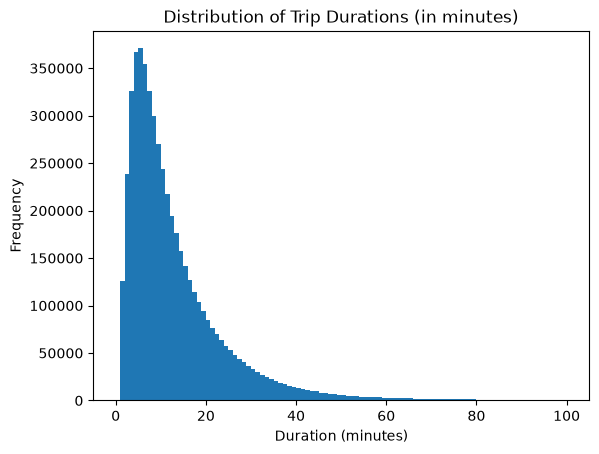

In [3]:
df['started_at'] = pd.to_datetime(df['started_at'])
df['ended_at'] = pd.to_datetime(df['ended_at'])

df['duration_min'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

plt.hist(df['duration_min'], bins=100, range=(0, 100))
plt.title('Distribution of Trip Durations (in minutes)')
plt.xlabel('Duration (minutes)')
plt.ylabel('Frequency')

2. What is the expected ride duration (the average ride duration)? What is the empirical variance
of ride duration? What is the probability that a ride lasts more than 20 minutes?


In [4]:
average_duration = df['duration_min'].mean()
duration_variance = df['duration_min'].var()
prob_greater_20 = df[df['duration_min'] > 20].shape[0] / df.shape[0]


print(f'Average trip duration: {average_duration} minutes')
print(f"Variance of trip durations: {duration_variance} minutes^2")
print(f"Probability of trip duration > 20 minutes: {prob_greater_20}")

Average trip duration: 13.486728892765743 minutes
Variance of trip durations: 162.87468623895418 minutes^2
Probability of trip duration > 20 minutes: 0.18912025763823476


3. What is the probability that a ride lasts more than 20 minutes conditional on the user being
a Citi Bike member?


In [5]:
citibike_member = df[df['member_casual'] == 'member']
prob_greater_20_member = citibike_member[citibike_member['duration_min'] > 20].shape[0] / citibike_member.shape[0]

print(f"Probability of trip duration > 20 minutes given citibike member: {prob_greater_20_member}")

Probability of trip duration > 20 minutes given citibike member: 0.154115787926601


4. Suppose that a ride lasts more than 25 minutes. What is the probability that this ride belongs
to a Citi Bike member?


In [6]:
ride_over_25 = df[df['duration_min'] > 25]
prob_citi_member = ride_over_25[ride_over_25['member_casual'] == 'member'].shape[0] / ride_over_25.shape[0]

print(f'Probability of being a citibike member given the trip duration > 25 minutes: {prob_citi_member}')

Probability of being a citibike member given the trip duration > 25 minutes: 0.6021240627983784


5. What is the expected ride duration of an electric bike? What is the expected ride duration of
a classic bike?

In [7]:
electric_bike_mean = df[df['rideable_type'] == 'electric_bike']['duration_min'].mean()
classic_bike_mean = df[df['rideable_type'] == 'classic_bike']['duration_min'].mean()

print(f'Average trip duration for electric bikes: {electric_bike_mean} minutes')
print(f'Average trip duration for classic bikes: {classic_bike_mean} minutes')

Average trip duration for electric bikes: 13.468248310798492 minutes
Average trip duration for classic bikes: 13.536927195731472 minutes


6. Suppose that a ride lasts less than 10 minutes. What is the probability that it uses an electric
bike? What is the probability that it uses a classic bike? Comment on the results.

In [8]:
ride_under_10 = df[df['duration_min'] < 10]
prob_classic_given_under_10 = ride_under_10[ride_under_10['rideable_type'] == 'classic_bike'].shape[0] / ride_under_10.shape[0]
prob_electric_given_under_10 = ride_under_10[ride_under_10['rideable_type'] == 'electric_bike'].shape[0] / ride_under_10.shape[0]

print(f'Probability of being a classic bike user given the trip duration < 10 minutes: {prob_classic_given_under_10}')
print(f'Probability of being an electric bike user given the trip duration < 10 minutes: {prob_electric_given_under_10}')

Probability of being a classic bike user given the trip duration < 10 minutes: 0.2795684954163652
Probability of being an electric bike user given the trip duration < 10 minutes: 0.7204315045836348


## Part I: Modeling Citi Bike stations using Markov chains

* Choose three popular Citi Bike stations in NYC with substantial activity. 
* Explain your selection. Split the day into two blocks of time, such as morning and evening, and focus only on weekdays. 
* Specify the hours included in each block. 
* Discretize each block into periods of 5 or 10 minutes, or justify another choice.

We chose two from Manhattan, and one from Brooklyn from the top 10 most active Citi Bike stations. We wanted to understand stations that were in relatively different locations 
* Broadway & E 14 St: Manhattan, East Village, 104 bikes
* 9 Ave & W 33 St: Manhattan, Midtown, 90 bikes
* N 7 St & Driggs Ave: Brooklyn, Williamsburg, 42 bikes

Broadway & E 14 St: 9,732 starts, 9,742 ends; saved clean-202608-citibike-tripdata/activity_histograms/Broadway_and_E_14_St_hourly_activity.png


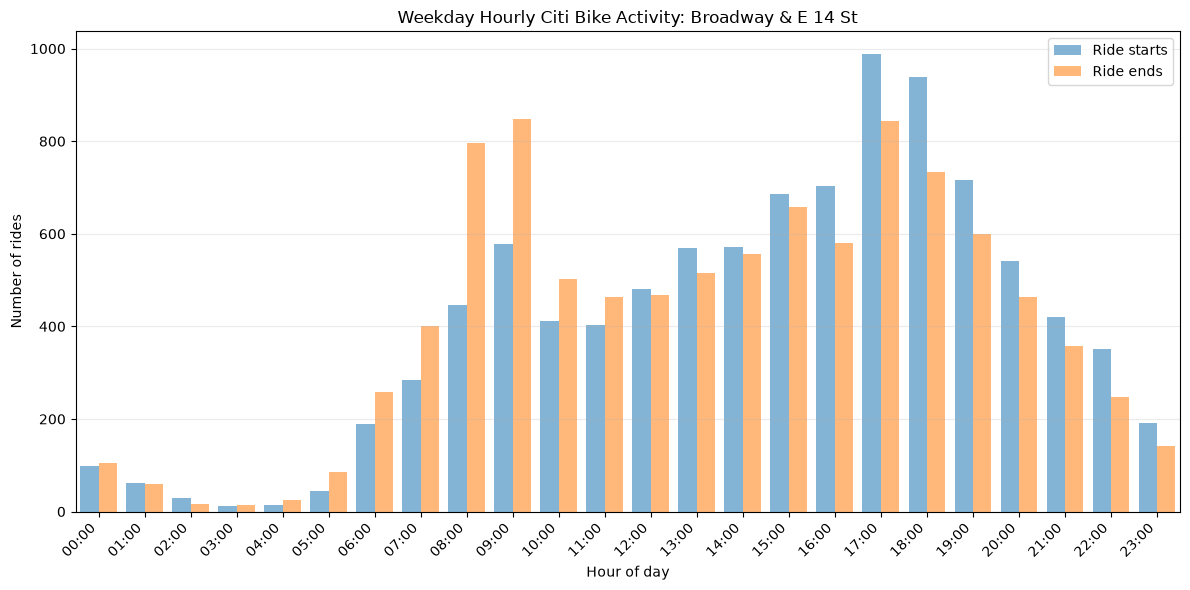

9 Ave & W 33 St: 11,399 starts, 11,497 ends; saved clean-202608-citibike-tripdata/activity_histograms/9_Ave_and_W_33_St_hourly_activity.png


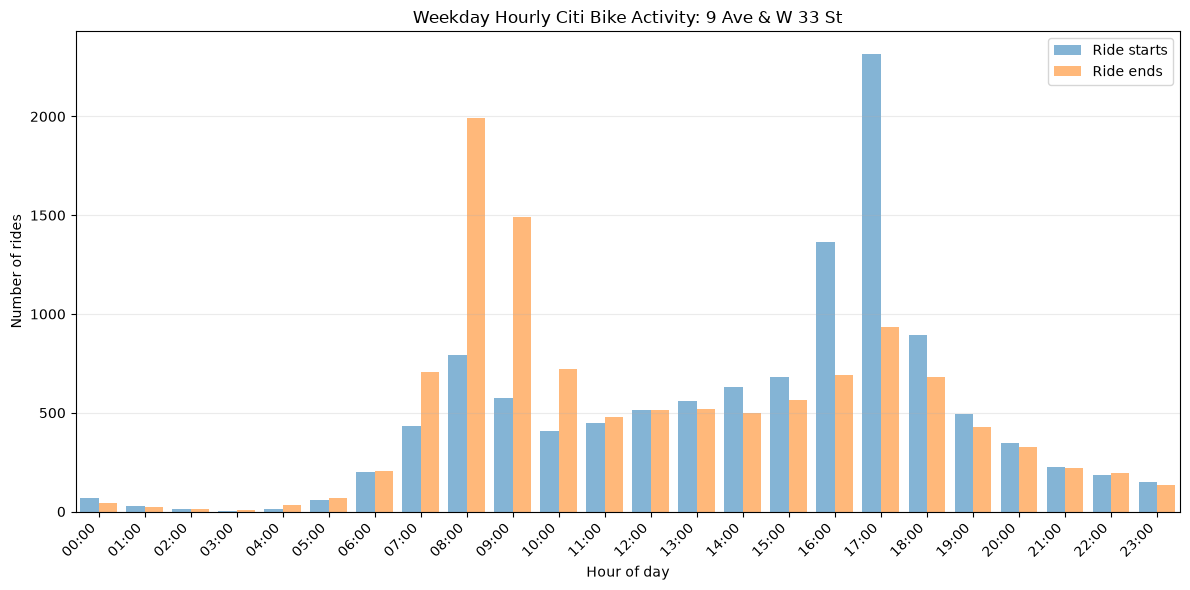

N 7 St & Driggs Ave: 8,150 starts, 8,052 ends; saved clean-202608-citibike-tripdata/activity_histograms/N_7_St_and_Driggs_Ave_hourly_activity.png


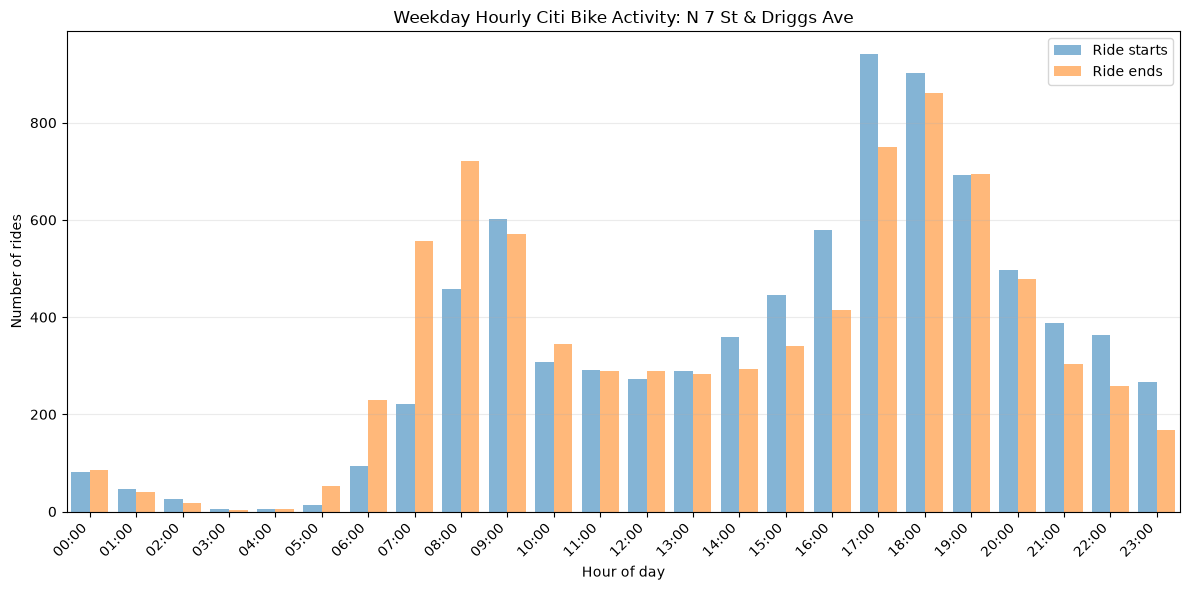

In [11]:
from pathlib import Path
# Import the tools needed to process timestamps and create the histograms.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the cleaned trip-data files created by the earlier cleaning step.
cleaned_dir = Path("clean-202608-citibike-tripdata")
cleaned_files = sorted(cleaned_dir.glob("*_cleaned.csv"))
# Stop with a clear error if the cleaned data has not been generated yet.
if not cleaned_files:
    raise FileNotFoundError(f"No cleaned CSV files found in {cleaned_dir}")

# These are the three stations selected earlier in the notebook.
stations = [
    "Broadway & E 14 St",
    "9 Ave & W 33 St",
    "N 7 St & Driggs Ave",
]
# Store each matching ride's start and end hour separately for every station.
activity = {station: {"start": [], "end": []} for station in stations}

# Read only the fields needed and process in chunks to keep memory use manageable.
for csv_file in cleaned_files:
    for chunk in pd.read_csv(
        csv_file,
        usecols=["started_at", "ended_at", "start_station_name", "end_station_name"],
        chunksize=250_000,
        low_memory=False,
    ):
        for station in stations:
            # Select rides that start or end at this station in the current chunk.
            start_times = chunk.loc[chunk["start_station_name"].eq(station), "started_at"]
            end_times = chunk.loc[chunk["end_station_name"].eq(station), "ended_at"]

            # Convert start timestamps and keep only Monday-Friday rides.
            # Invalid timestamps are ignored rather than counted as an hour.
            if not start_times.empty:
                start_datetimes = pd.to_datetime(start_times, errors="coerce")
                # Monday-Friday have day-of-week numbers 0 through 4.
                weekday_starts = start_datetimes[start_datetimes.dt.day_of_week < 5]
                start_hours = weekday_starts.dt.hour.dropna()
                if not start_hours.empty:
                    # Keep hours as small integers to reduce memory use.
                    activity[station]["start"].append(start_hours.to_numpy(dtype=np.int8))

            # Count an arrival only when its end timestamp falls on a weekday.
            if not end_times.empty:
                end_datetimes = pd.to_datetime(end_times, errors="coerce")
                weekday_ends = end_datetimes[end_datetimes.dt.day_of_week < 5]
                end_hours = weekday_ends.dt.hour.dropna()
                if not end_hours.empty:
                    activity[station]["end"].append(end_hours.to_numpy(dtype=np.int8))

# Save generated histogram images beside the cleaned CSV data.
plot_dir = cleaned_dir / "activity_histograms"
plot_dir.mkdir(parents=True, exist_ok=True)
# Half-integer edges center one histogram bin on each clock hour.
bins = np.arange(-0.5, 24.5, 1)
hours = np.arange(24)

# Create one separate start-versus-end histogram for each selected station.
for station in stations:
    # Make missing activity explicit instead of creating a misleading blank plot.
    if not activity[station]["start"] or not activity[station]["end"]:
        raise ValueError(f"No start or end activity found for {station}")
    # Join hours from every CSV chunk so each chart covers the complete dataset.
    start_hours = np.concatenate(activity[station]["start"])
    end_hours = np.concatenate(activity[station]["end"])

    # Overlay transparent blue start bars and orange end bars on the same axes.
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.hist(
        [start_hours, end_hours],
        bins=bins,
        color=["tab:blue", "tab:orange"],
        alpha=0.55,
        label=["Ride starts", "Ride ends"],
    )
    # Label every hour and identify the station and activity counts.
    ax.set(
        title=f"Weekday Hourly Citi Bike Activity: {station}",
        xlabel="Hour of day",
        ylabel="Number of rides",
        xticks=hours,
        xlim=(-0.5, 23.5),
    )
    ax.set_xticklabels([f"{hour:02d}:00" for hour in hours], rotation=45, ha="right")
    # Add a legend and light horizontal guides to compare the two series.
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()

    # Use a filesystem-safe station name in the PNG output filename.
    plot_file = plot_dir / f"{station.replace(' ', '_').replace('&', 'and')}_hourly_activity.png"
    fig.savefig(plot_file, dpi=150, bbox_inches="tight")
    # Report the counts, display the plot, and release its memory afterward.
    print(f"{station}: {len(start_hours):,} starts, {len(end_hours):,} ends; saved {plot_file}")
    plt.show()
    plt.close(fig)

Based on the graphs i think the days can be broken into 04:00 - 12:00 and 12:00 - 04:00 the next day. However, to keep it simple we are just going to break the days into 00:00 - 12:00 and 12:00 - 24:00.

### Part 1: Weekday trips involving the three selected docks

Keep rides that start or end at one of the selected docks. Use the ride's start date to exclude weekends and set `time_block` to 1 for morning starts (00:00-11:59) or 0 for evening starts (12:00-23:59).

In [12]:
# Import tools for locating the cleaned files and processing their CSV rows.
from pathlib import Path
import pandas as pd

# Read the previously cleaned data and write the Part 1 subset to its own folder.
input_dir = Path("clean-202608-citibike-tripdata")
output_dir = Path("part1-citibike-tripdata")
source_files = sorted(input_dir.glob("*_cleaned.csv"))

# Stop rather than silently creating an empty dataset if the cleaned inputs are missing.
if not source_files:
    raise FileNotFoundError(f"No cleaned CSV files found in {input_dir}")

# Use the three stations selected for the Part 1 analysis.
stations = {
    "Broadway & E 14 St",
    "9 Ave & W 33 St",
    "N 7 St & Driggs Ave",
}
output_dir.mkdir(parents=True, exist_ok=True)

# Process in chunks so the multi-million-row dataset does not need to fit in memory.
chunk_size = 250_000
totals = {
    "rows_before": 0,
    "involving_selected_docks": 0,
    "weekend_removed": 0,
    "invalid_start_removed": 0,
    "rows_retained": 0,
    "morning": 0,
    "evening": 0,
}

for source_file in source_files:
    # Keep one output shard per input shard, with a clear Part 1 filename.
    output_file = output_dir / f"{source_file.stem.replace('_cleaned', '')}_part1.csv"
    file_totals = {key: 0 for key in totals}

    for chunk_number, chunk in enumerate(
        pd.read_csv(source_file, chunksize=chunk_size, low_memory=False)
    ):
        # Identify trips touching at least one of the three selected docks.
        at_selected_start = chunk["start_station_name"].isin(stations)
        at_selected_end = chunk["end_station_name"].isin(stations)
        involves_selected_dock = at_selected_start | at_selected_end

        # Use the trip start time to determine both its weekday and its time block.
        start_time = pd.to_datetime(chunk["started_at"], errors="coerce")
        valid_start_time = start_time.notna()
        weekday = valid_start_time & (start_time.dt.day_of_week < 5)

        # Keep only weekday trips that start or end at a selected dock.
        keep_trip = involves_selected_dock & weekday
        part1_chunk = chunk.loc[keep_trip].copy()

        # Label starts before noon as morning (1) and starts at/after noon as evening (0).
        morning = start_time.loc[keep_trip].dt.hour < 12
        part1_chunk["time_block"] = morning.astype("int8")

        # Track the filter results and time-block counts for the summary below.
        file_totals["rows_before"] += len(chunk)
        file_totals["involving_selected_docks"] += int(involves_selected_dock.sum())
        file_totals["weekend_removed"] += int(
            (involves_selected_dock & valid_start_time & ~weekday).sum()
        )
        file_totals["invalid_start_removed"] += int(
            (involves_selected_dock & ~valid_start_time).sum()
        )
        file_totals["rows_retained"] += len(part1_chunk)
        file_totals["morning"] += int(morning.sum())
        file_totals["evening"] += int((~morning).sum())

        # Write the first chunk with a header and append subsequent chunks without one.
        part1_chunk.to_csv(
            output_file,
            mode="w" if chunk_number == 0 else "a",
            header=chunk_number == 0,
            index=False,
        )

    # Add this shard's counts to the all-files summary and report its output.
    for key, value in file_totals.items():
        totals[key] += value
    print(
        f"{source_file.name}: {file_totals['rows_retained']:,} weekday trips involving "
        f"the selected docks saved to {output_file}"
    )

# Report the filtering totals and morning/evening assignments for the complete dataset.
print("\nPart 1 dataset summary")
print(f"Input rows: {totals['rows_before']:,}")
print(f"Trips involving at least one selected dock: {totals['involving_selected_docks']:,}")
print(f"Weekend trips removed: {totals['weekend_removed']:,}")
print(f"Trips with invalid start time removed: {totals['invalid_start_removed']:,}")
print(f"Weekday trips retained: {totals['rows_retained']:,}")
print(f"Morning time_block=1: {totals['morning']:,}")
print(f"Evening time_block=0: {totals['evening']:,}")
print(f"Part 1 CSV files saved in: {output_dir}")

202608-citibike-tripdata_1_cleaned.csv: 13,498 weekday trips involving the selected docks saved to part1-citibike-tripdata/202608-citibike-tripdata_1_part1.csv
202608-citibike-tripdata_2_cleaned.csv: 11,520 weekday trips involving the selected docks saved to part1-citibike-tripdata/202608-citibike-tripdata_2_part1.csv
202608-citibike-tripdata_3_cleaned.csv: 11,256 weekday trips involving the selected docks saved to part1-citibike-tripdata/202608-citibike-tripdata_3_part1.csv
202608-citibike-tripdata_4_cleaned.csv: 9,029 weekday trips involving the selected docks saved to part1-citibike-tripdata/202608-citibike-tripdata_4_part1.csv
202608-citibike-tripdata_5_cleaned.csv: 12,246 weekday trips involving the selected docks saved to part1-citibike-tripdata/202608-citibike-tripdata_5_part1.csv
202608-citibike-tripdata_6_cleaned.csv: 783 weekday trips involving the selected docks saved to part1-citibike-tripdata/202608-citibike-tripdata_6_part1.csv

Part 1 dataset summary
Input rows: 5,240,21